# Batched source integration with `hblteuk.jax`

Phase 3 of the GPU port: **Teukolsky-mode amplitudes for thousands of
$(\ell, m, n)$ modes in one batched pipeline** — spheroidal eigensolve →
radial solutions → source integration.

The amplitude of mode $(\ell, m, n)$ is the $n$-th Fourier coefficient of a
phase-stripped integrand $J(q_r)$ over the full radial period. Two
extraction methods are provided:

- `method="quad"` — staggered uniform rules (the CPU algorithm, batched);
- `method="fft"` — a single `ifft` picks out the coefficient **and** the
  spectrum tail gives a built-in aliasing error estimate.

Design notes: `dev/GPU_PLAN.md` §2.3, `dev/PHASE3.md`; cross-validation in
`examples/jax_source_validation.ipynb`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax

from hblteuk.geo import MiniGeo
from hblteuk.collocode import generate_subdomain_list
from hblteuk.teuk import sigma_r
from hblteuk.jax import (spheroidal_eigs_batched, solve_homogeneous_batch,
                         orbit_samples, equatorial_swsh_values,
                         integrate_source_batch)

C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]  # Okabe-Ito, fixed order

orbit = MiniGeo(0.9, 10.0, 0.2, 1.0)   # eccentric equatorial
a = orbit.a
kappa = np.sqrt(1 - a**2)
smin = sigma_r(orbit.radial_roots[0], kappa)
smax = sigma_r(orbit.radial_roots[1], kappa)
subs_up = generate_subdomain_list([0, smax], 150, "arcsinh7")
subs_in = generate_subdomain_list([1, smin], 150, "arcsinh7")
print("devices:", jax.devices())

devices: [CpuDevice(id=0)]


## 1. Mode table: full $(\ell, m, n)$ grid

Every radiative mode with $\ell \le 8$, $|n| \le 8$ — the kind of table an
adiabatic-inspiral flux computation needs.

In [2]:
lmax, nmax = 8, 8
MODES = [(l, m, n) for l in range(2, lmax + 1) for m in range(-l, l + 1)
         if m != 0 for n in range(-nmax, nmax + 1)]
l_arr = np.array([c[0] for c in MODES])
m_arr = np.array([c[1] for c in MODES])
n_arr = np.array([c[2] for c in MODES])
omega = m_arr * orbit.frequencies[2] + n_arr * orbit.frequencies[0]
keep = np.abs(omega) > 1e-8   # drop accidental omega ~ 0 (static) modes
l_arr, m_arr, n_arr, omega = (x[keep] for x in (l_arr, m_arr, n_arr, omega))
B = len(l_arr)
print(f"B = {B} radiative modes")

B = 1190 radiative modes


## 2. The three batched stages

In [3]:
t0 = time.perf_counter()
lam, coeffs, lmin = spheroidal_eigs_batched(-2, l_arr, m_arr, a * omega)
lam = np.asarray(lam)
t1 = time.perf_counter()

hom = solve_homogeneous_batch(-2, kappa, lam, m_arr * a, omega,
                              subs_up, subs_in, n=32)
hom.coeffs_up.block_until_ready()
t2 = time.perf_counter()

samples = orbit_samples(orbit, nsamples=2**10)
S, dS, d2S = equatorial_swsh_values(-2, m_arr, lmin, coeffs, lam, a * omega)
res = integrate_source_batch(samples, lam, m_arr, n_arr, omega,
                             S, dS, d2S, hom, subs_up, subs_in, method="fft")
res.amplitudes.block_until_ready()
t3 = time.perf_counter()

amps = np.asarray(res.amplitudes)     # (B, 2): [In, Up]
errs = np.asarray(res.errors)
print(f"spheroidal {t1-t0:.2f}s | radial {t2-t1:.2f}s | source {t3-t2:.2f}s")
print(f"end-to-end: {t3-t0:.1f}s for B = {B} "
      f"({1e3*(t3-t0)/B:.2f} ms/mode on {jax.devices()[0].platform.upper()}-JAX)")

spheroidal 0.34s | radial 1.60s | source 1.28s
end-to-end: 3.2s for B = 1190 (2.71 ms/mode on CPU-JAX)


## 3. Amplitude spectra

$|Z^\infty_{\ell m n}|$ (Up amplitudes) across the radial-harmonic tower:
the eccentricity-driven $n$-spectrum for a few $(\ell, m)$ pairs. Open
markers flag modes whose built-in error estimate exceeds $10^{-6}$ —
the tiny far-tail amplitudes approaching the cancellation floor.

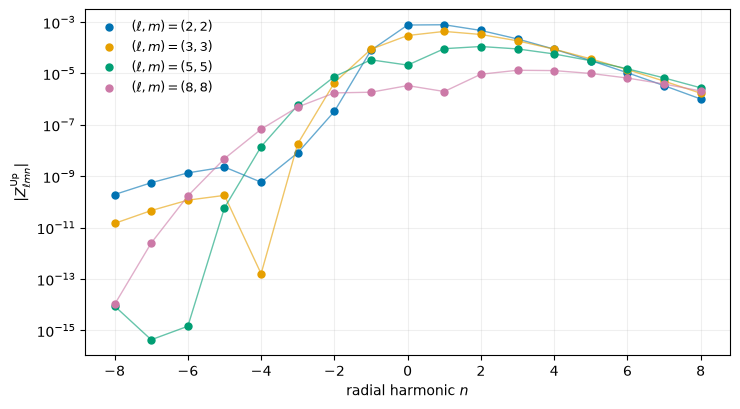

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for color, (l, m) in zip(C, [(2, 2), (3, 3), (5, 5), (8, 8)]):
    sel = (l_arr == l) & (m_arr == m)
    nn, aa, ee = n_arr[sel], np.abs(amps[sel, 1]), errs[sel, 1]
    order = np.argsort(nn)
    nn, aa, ee = nn[order], aa[order], ee[order]
    good = ee < 1e-6
    ax.semilogy(nn, aa, "-", lw=1, color=color, alpha=0.6)
    ax.semilogy(nn[good], aa[good], "o", ms=5, color=color,
                label=rf"$(\ell,m)=({l},{m})$")
    ax.semilogy(nn[~good], aa[~good], "o", ms=5, mfc="none", color=color)
ax.set_xlabel(r"radial harmonic $n$")
ax.set_ylabel(r"$|Z^{\rm Up}_{\ell m n}|$")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()

## 4. Built-in error estimates

`method="fft"` reports max(aliasing tail / coefficient, cancellation
floor) per mode. The map shows where the mode table is trustworthy at a
glance — estimates grow toward the spectrum edges exactly where the
$n$-tower should be truncated or `nsamples` increased.

modes with error estimate < 1e-8: 1006 / 1190


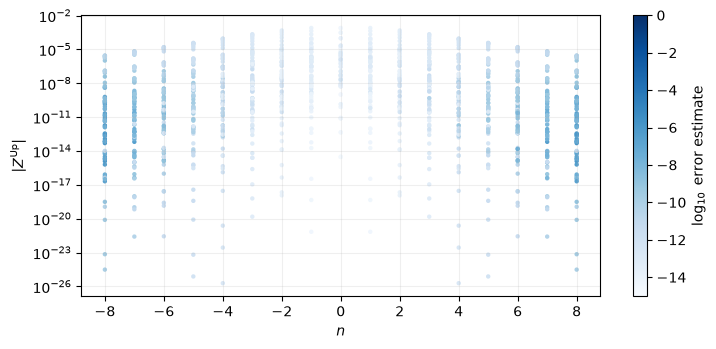

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
sc = ax.scatter(n_arr, np.abs(amps[:, 1]), c=np.log10(errs[:, 1]),
                cmap="Blues", s=10, vmin=-15, vmax=0, linewidths=0)
ax.set_yscale("log")
ax.set_xlabel(r"$n$")
ax.set_ylabel(r"$|Z^{\rm Up}|$")
fig.colorbar(sc, label=r"$\log_{10}$ error estimate")
ax.grid(alpha=0.2)
plt.tight_layout()
print(f"modes with error estimate < 1e-8: "
      f"{int(np.sum(errs.max(axis=1) < 1e-8))} / {B}")

## Next

Phase 4 assembles these amplitudes into fluxes/waveforms (batched mode
summation) and routes the whole grid generator through this pipeline.
`cluster/benchmark_gpu.py` runs the same stages on the A100s.